In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
from scipy.stats import kurtosis, skew
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.utils import resample
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
train_dir = '/content/drive/MyDrive/train-emotions'
test_dir = '/content/drive/MyDrive/test-emotions'

Mounted at /content/drive


Total de imágenes en train: 10694
Imágenes por emoción en train: {'angry': 3480, 'happy': 7214}
Total de imágenes en test: 2731
Imágenes por emoción en test: {'angry': 957, 'happy': 1774}


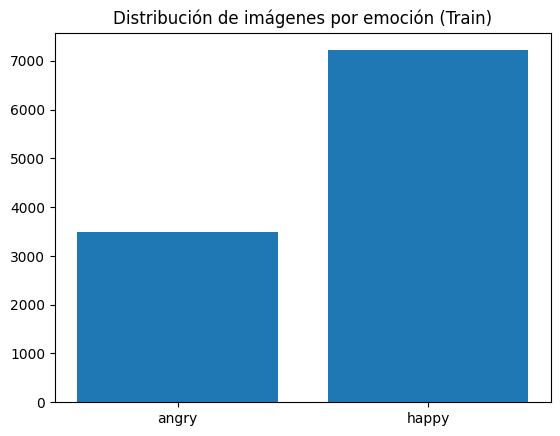

In [ ]:
#@title CANTIDAD DE IMAGENES DEL DATASET
def count_images_in_folders(base_path):
    emotions = ['angry', 'happy']
    total_count = 0
    count_per_emotion = {}

    for emotion in emotions:
        emotion_path = os.path.join(base_path, emotion)
        count = len([img for img in os.listdir(emotion_path) if img.endswith('.jpg')])
        count_per_emotion[emotion] = count
        total_count += count

    return total_count, count_per_emotion

train_total, train_counts = count_images_in_folders(train_dir)
test_total, test_counts = count_images_in_folders(test_dir)

print(f"Total de imágenes en train: {train_total}")
print(f"Imágenes por emoción en train: {train_counts}")

print(f"Total de imágenes en test: {test_total}")
print(f"Imágenes por emoción en test: {test_counts}")

# Gráfico de barras para el balance de clases
labels = list(train_counts.keys())
values = list(train_counts.values())

plt.bar(labels, values)
plt.title('Distribución de imágenes por emoción (Train)')
plt.show()

In [ ]:
#@title FILTROS Y CARACTERISTICAS
def normalize_image(image):
    min_val = np.min(image)
    max_val = np.max(image)
    if max_val - min_val == 0:
        return image  # Si la imagen es constante, devolver la misma
    else:
        return (image - min_val) / (max_val - min_val)

def calculate_statistics(image):
    mean_val = np.mean(image)
    var_val = np.var(image)
    kurt_val = kurtosis(image, axis=None)  # Curtosis sobre todos los píxeles
    skew_val = skew(image, axis=None)  # Asimetría sobre todos los píxeles
    return mean_val, var_val, kurt_val, skew_val

def preprocess_image(image):
    # Normalizar la imagen primero
    image_normalized = normalize_image(image)
    image_normalized = np.float32(image_normalized) #es necesario convertirlo a

    # Aplicar filtro bilateral para suavizado
    image_bilateral = cv2.bilateralFilter(image_normalized, 9, 75, 75)

    # Detección de bordes con Sobel (derivadas en x e y)
    sobelx = cv2.Sobel(image_normalized, cv2.CV_64F, 1, 0, ksize=5)
    sobely = cv2.Sobel(image_normalized, cv2.CV_64F, 0, 1, ksize=5)
    image_edges = cv2.magnitude(sobelx, sobely)  # Magnitud de los bordes

    # Calcular estadísticas para ambos filtros
    bilateral_stats = calculate_statistics(image_bilateral)
    sobel_stats = calculate_statistics(image_edges)

    # Retornar todas las estadísticas como características
    features = np.hstack((bilateral_stats, sobel_stats))  # Concatenar todas las características
    return features

def augment_image(image):
    """Genera una versión aumentada de la imagen con rotación y recorte."""
    angle = np.random.uniform(-20, 20)  # Rotación aleatoria entre -20 y 20 grados
    h, w = image.shape
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1)
    rotated = cv2.warpAffine(image, M, (w, h))

    # Recorte aleatorio (zoom)
    x_start = np.random.randint(0, w // 4)
    y_start = np.random.randint(0, h // 4)
    cropped = rotated[y_start:y_start + (h - y_start), x_start:x_start + (w - x_start)]

    # Redimensionar de nuevo a 48x48
    augmented = cv2.resize(cropped, (48, 48))
    return augmented

def augment_class_to_balance(images, target_size):
    """
    Genera suficientes imágenes aumentadas para igualar el tamaño objetivo.
    """
    augmented_images = []
    while len(augmented_images) + len(images) < target_size:
        for image in images:
            augmented_images.append(augment_image(image))
            if len(augmented_images) + len(images) >= target_size:
                break  # Detener si alcanzamos el tamaño deseado

    return images + augmented_images


def preprocess_images_with_balancing(folder_path):
    features = []
    labels = []

    # Definir las etiquetas para las carpetas
    emotion_folders = {'angry': 0, 'happy': 1}

    for emotion, label in emotion_folders.items():
        emotion_folder = os.path.join(folder_path, emotion)

        print(f"Procesando carpeta: {emotion_folder}")
        if not os.path.exists(emotion_folder):
            print(f"Carpeta {emotion_folder} no encontrada")
            continue

        count = 0
        for filename in os.listdir(emotion_folder):
            if filename.endswith('.jpg'):
                image_path = os.path.join(emotion_folder, filename)
                image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

                # Aplicar preprocesamiento
                image_features = preprocess_image(image)
                features.append(image_features)
                labels.append(label)
                count += 1

        print(f"Total de imágenes procesadas para {emotion}: {count}")

    # Verificar balanceo
    angry_count = labels.count(0)
    happy_count = labels.count(1)

    print(f"Antes del balanceo - Angry: {angry_count}, Happy: {happy_count}")

    # Balancear mediante sobremuestreo para igualar las clases
    if angry_count < happy_count:
        difference = happy_count - angry_count
        for i in range(difference):
            idx = np.random.choice(np.where(np.array(labels) == 0)[0])
            features.append(features[idx])
            labels.append(0)

    print(f"Después del balanceo - Angry: {labels.count(0)}, Happy: {labels.count(1)}")

    return np.array(features), np.array(labels)


train_features, train_labels = preprocess_images_with_balancing(train_dir)
test_features, test_labels = preprocess_images_with_balancing(test_dir)
print(f"Total de características: {train_features.shape}")
print(f"Total de etiquetas: {len(train_labels)}")

Procesando carpeta: /content/drive/MyDrive/train-emotions/angry
Total de imágenes procesadas para angry: 3480
Procesando carpeta: /content/drive/MyDrive/train-emotions/happy
Total de imágenes procesadas para happy: 7214
Antes del balanceo - Angry: 3480, Happy: 7214
Después del balanceo - Angry: 7214, Happy: 7214
Procesando carpeta: /content/drive/MyDrive/test-emotions/angry
Total de imágenes procesadas para angry: 957
Procesando carpeta: /content/drive/MyDrive/test-emotions/happy
Total de imágenes procesadas para happy: 1774
Antes del balanceo - Angry: 957, Happy: 1774
Después del balanceo - Angry: 1774, Happy: 1774
Total de características: (14428, 8)
Total de etiquetas: 14428


Precisión: 0.60
=== Classification Report ===
              precision    recall  f1-score   support

       Angry       0.60      0.57      0.59      1774
       Happy       0.59      0.62      0.61      1774

    accuracy                           0.60      3548
   macro avg       0.60      0.60      0.60      3548
weighted avg       0.60      0.60      0.60      3548

=== Validación Cruzada ===
Precisión de SVM con Validación Cruzada: 0.61 ± 0.01
=== Confusion Matrix ===
[[1010  764]
 [ 668 1106]]


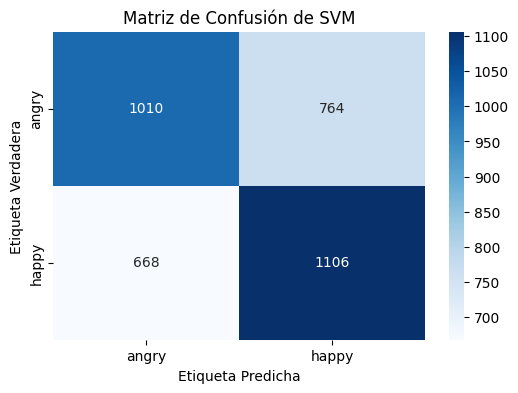

In [ ]:
#@title ENTRENAR SVM

def plot_confusion_matrix(cm, title):
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['angry', 'happy'], yticklabels=['angry', 'happy'])
    plt.ylabel('Etiqueta Verdadera')
    plt.xlabel('Etiqueta Predicha')
    plt.title(title)
    plt.show()

# Escalar los datos
scaler = StandardScaler()
train_features_scaled = scaler.fit_transform(train_features)
test_features_scaled = scaler.transform(test_features)

# Inicializar y entrenar el modelo SVM
svm = SVC(kernel='rbf', random_state=42, class_weight='balanced')
# svm = SVC(kernel='rbf', C=2.0, gamma='scale', random_state=42)
svm.fit(train_features_scaled, train_labels)

# Evaluación del modelo
svm_predictions = svm.predict(test_features_scaled)

# Mostrar los resultados
svm_accuracy = accuracy_score(test_labels, svm_predictions)
print(f"Precisión: {svm_accuracy:.2f}")

print("=== Classification Report ===")
print(classification_report(test_labels, svm_predictions, target_names=["Angry", "Happy"]))

print("=== Validación Cruzada ===")
svm_cv_scores = cross_val_score(svm, train_features_scaled, train_labels, cv=5)
print(f"Precisión de SVM con Validación Cruzada: {svm_cv_scores.mean():.2f} ± {svm_cv_scores.std():.2f}")

print("=== Confusion Matrix ===")
svm_conf_matrix = confusion_matrix(test_labels, svm_predictions)
print(svm_conf_matrix)
plot_confusion_matrix(svm_conf_matrix, "Matriz de Confusión de SVM")

Precisión: 0.56
=== Classification Report ===
              precision    recall  f1-score   support

       angry       0.57      0.51      0.54      1774
       happy       0.55      0.61      0.58      1774

    accuracy                           0.56      3548
   macro avg       0.56      0.56      0.56      3548
weighted avg       0.56      0.56      0.56      3548

=== Validación Cruzada ===
Precisión de KNN con Validación Cruzada: 0.66 ± 0.04
=== Confusion Matrix ===
[[ 908  866]
 [ 695 1079]]


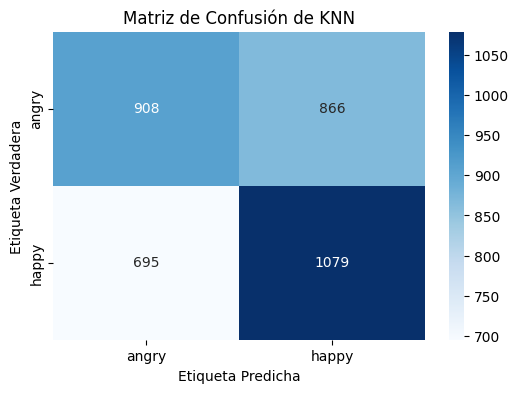

In [ ]:
#@title ENTRENAR KNN

# Escalar los datos
scaler = StandardScaler()
train_features_scaled = scaler.fit_transform(train_features)
test_features_scaled = scaler.transform(test_features)

# Entrenar y evaluar KNN
knn_classifier = KNeighborsClassifier(n_neighbors=5)
knn_classifier.fit(train_features_scaled, train_labels)
knn_predictions = knn_classifier.predict(test_features_scaled)

#Mostrar los resultados
knn_accuracy = accuracy_score(test_labels, knn_predictions)
print(f"Precisión: {knn_accuracy:.2f}")
knn_conf_matrix = confusion_matrix(test_labels, knn_predictions)
print("=== Classification Report ===")
print(classification_report(test_labels, knn_predictions, target_names=['angry', 'happy']))

print("=== Validación Cruzada ===")
knn_cv_scores = cross_val_score(knn_classifier, train_features_scaled, train_labels, cv=5)
print(f"Precisión de KNN con Validación Cruzada: {knn_cv_scores.mean():.2f} ± {knn_cv_scores.std():.2f}")

print("=== Confusion Matrix ===")
print(knn_conf_matrix)
plot_confusion_matrix(knn_conf_matrix, "Matriz de Confusión de KNN")

In [ ]:
#@title PROCESAR IMAGENES Y BALANCEAR APLICANDO SUBMUESTREO (UNDERSAMPLE)
# Función para preprocesar las imágenes de una carpeta (completo)
def preprocess_images_in_folder(folder_path):
    features = []
    labels = []

    # Definir las etiquetas para las carpetas
    emotion_folders = {'angry': 0, 'happy': 1}

    # Recorrer las carpetas de emociones
    for emotion, label in emotion_folders.items():
        emotion_folder = os.path.join(folder_path, emotion)

        print(f"Procesando carpeta: {emotion_folder}")
        if not os.path.exists(emotion_folder):
            print(f"Carpeta {emotion_folder} no encontrada")
            continue

        count = 0
        for filename in os.listdir(emotion_folder):
            if filename.endswith('.jpg'):
                image_path = os.path.join(emotion_folder, filename)
                image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

                # Aplicar preprocesamiento y obtener características
                image_features = preprocess_image(image)

                features.append(image_features)
                labels.append(label)

                count += 1

        print(f"Total de imágenes procesadas para {emotion}: {count}")

    return features, labels

# Procesar imágenes de entrenamiento y prueba
train_features, train_labels = preprocess_images_in_folder(train_dir)
test_features, test_labels = preprocess_images_in_folder(test_dir)

# Función para balancear datos (submuestreo)
def balance_data_undersample(features, labels):
    data = np.column_stack((features, labels))

    # Separar por clases
    angry_data = data[data[:, -1] == 0]
    happy_data = data[data[:, -1] == 1]

    # Submuestrear la clase mayoritaria ('happy')
    happy_downsampled = resample(happy_data, replace=False, n_samples=len(angry_data), random_state=42)

    # Reunir las clases balanceadas
    balanced_data = np.vstack((angry_data, happy_downsampled))

    # Separar características y etiquetas nuevamente
    balanced_features = balanced_data[:, :-1]
    balanced_labels = balanced_data[:, -1]

    return balanced_features, balanced_labels

# Escalar los datos
scaler = StandardScaler()
all_features = np.vstack((train_features, test_features))
scaler.fit(all_features)

train_features_scaled = scaler.transform(train_features)
test_features_scaled = scaler.transform(test_features)

# Balancear los datos de entrenamiento usando submuestreo
train_features_balanced, train_labels_balanced = balance_data_undersample(train_features_scaled, train_labels)

Procesando carpeta: /content/drive/MyDrive/train-emotions/angry
Total de imágenes procesadas para angry: 3480
Procesando carpeta: /content/drive/MyDrive/train-emotions/happy
Total de imágenes procesadas para happy: 7214
Procesando carpeta: /content/drive/MyDrive/test-emotions/angry
Total de imágenes procesadas para angry: 957
Procesando carpeta: /content/drive/MyDrive/test-emotions/happy
Total de imágenes procesadas para happy: 1774


=== SVM ===
Precisión: 0.56
Informe de Clasificación:
              precision    recall  f1-score   support

       angry       0.59      0.39      0.47      1774
       happy       0.54      0.73      0.62      1774

    accuracy                           0.56      3548
   macro avg       0.56      0.56      0.54      3548
weighted avg       0.56      0.56      0.54      3548

=== KNN ===
Precisión: 0.56
Informe de Clasificación:
              precision    recall  f1-score   support

       angry       0.57      0.51      0.54      1774
       happy       0.56      0.61      0.58      1774

    accuracy                           0.56      3548
   macro avg       0.56      0.56      0.56      3548
weighted avg       0.56      0.56      0.56      3548



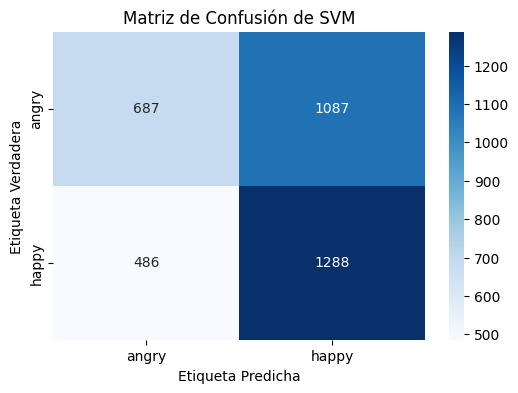

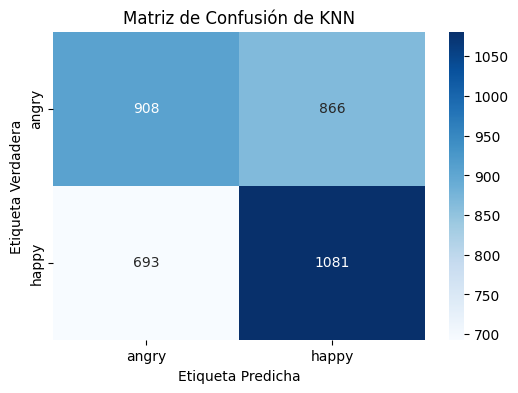

=== Validación Cruzada ===
Precisión de SVM con Validación Cruzada: 0.55 ± 0.01
Precisión de KNN con Validación Cruzada: 0.66 ± 0.04
=== Métricas Adicionales ===
SVM - Precisión: 0.54, Recall: 0.73, F1-Score: 0.62
KNN - Precisión: 0.56, Recall: 0.61, F1-Score: 0.58


In [ ]:
#@title COMPLETO - NO EJECUTAR
# Convertir a arrays de NumPy
train_features = np.array(train_features)
train_labels = np.array(train_labels)
test_features = np.array(test_features)
test_labels = np.array(test_labels)

# Escalado de características
all_features = np.vstack((train_features, test_features))
scaler = StandardScaler()
scaler.fit(all_features)

train_features_scaled = scaler.transform(train_features)
test_features_scaled = scaler.transform(test_features)

# Entrenar y evaluar SVM
svm_classifier = SVC(kernel='linear', probability=True, random_state=42)
svm_classifier.fit(train_features_scaled, train_labels)
svm_predictions = svm_classifier.predict(test_features_scaled)

# Entrenar y evaluar KNN
knn_classifier = KNeighborsClassifier(n_neighbors=5)
knn_classifier.fit(train_features_scaled, train_labels)
knn_predictions = knn_classifier.predict(test_features_scaled)

# Evaluación de SVM
print("=== SVM ===")
svm_accuracy = accuracy_score(test_labels, svm_predictions)
print(f"Precisión: {svm_accuracy:.2f}")
svm_conf_matrix = confusion_matrix(test_labels, svm_predictions)
print("Informe de Clasificación:")
print(classification_report(test_labels, svm_predictions, target_names=['angry', 'happy']))

# Evaluación de KNN
print("=== KNN ===")
knn_accuracy = accuracy_score(test_labels, knn_predictions)
print(f"Precisión: {knn_accuracy:.2f}")
knn_conf_matrix = confusion_matrix(test_labels, knn_predictions)
print("Informe de Clasificación:")
print(classification_report(test_labels, knn_predictions, target_names=['angry', 'happy']))

# Visualización de las Matrices de Confusión
def plot_confusion_matrix(cm, title):
    plt.figure(figsize=(6,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['angry', 'happy'], yticklabels=['angry', 'happy'])
    plt.ylabel('Etiqueta Verdadera')
    plt.xlabel('Etiqueta Predicha')
    plt.title(title)
    plt.show()

plot_confusion_matrix(svm_conf_matrix, "Matriz de Confusión de SVM")
plot_confusion_matrix(knn_conf_matrix, "Matriz de Confusión de KNN")

# Validación Cruzada
print("=== Validación Cruzada ===")
svm_cv_scores = cross_val_score(svm_classifier, train_features_scaled, train_labels, cv=5)
print(f"Precisión de SVM con Validación Cruzada: {svm_cv_scores.mean():.2f} ± {svm_cv_scores.std():.2f}")

knn_cv_scores = cross_val_score(knn_classifier, train_features_scaled, train_labels, cv=5)
print(f"Precisión de KNN con Validación Cruzada: {knn_cv_scores.mean():.2f} ± {knn_cv_scores.std():.2f}")

# Informe adicional de precisión, recall y F1-Score
print("=== Métricas Adicionales ===")
# SVM
svm_precision = precision_score(test_labels, svm_predictions, average='binary')
svm_recall = recall_score(test_labels, svm_predictions, average='binary')
svm_f1 = f1_score(test_labels, svm_predictions, average='binary')
print(f"SVM - Precisión: {svm_precision:.2f}, Recall: {svm_recall:.2f}, F1-Score: {svm_f1:.2f}")

# KNN
knn_precision = precision_score(test_labels, knn_predictions, average='binary')
knn_recall = recall_score(test_labels, knn_predictions, average='binary')
knn_f1 = f1_score(test_labels, knn_predictions, average='binary')
print(f"KNN - Precisión: {knn_precision:.2f}, Recall: {knn_recall:.2f}, F1-Score: {knn_f1:.2f}")

# # Ajuste de Hiperparámetros
# # SVM
# svm_param_grid = {
#     'C': [0.1, 1, 10, 100],
#     'kernel': ['linear', 'rbf', 'poly'],
#     'gamma': ['scale', 'auto']
# }
# svm_grid = GridSearchCV(SVC(probability=True, random_state=42), svm_param_grid, cv=5, scoring='accuracy')
# svm_grid.fit(train_features_scaled, train_labels)
# print(f"Mejores parámetros para SVM: {svm_grid.best_params_}")
# print(f"Mejor precisión de SVM: {svm_grid.best_score_:.2f}")
# best_svm = svm_grid.best_estimator_
# svm_best_predictions = best_svm.predict(test_features_scaled)
# print(f"Precisión del mejor SVM: {accuracy_score(test_labels, svm_best_predictions):.2f}")

# # KNN
# knn_param_grid = {
#     'n_neighbors': list(range(1, 31)),
#     'weights': ['uniform', 'distance'],
#     'metric': ['euclidean', 'manhattan', 'minkowski']
# }
# knn_grid = GridSearchCV(KNeighborsClassifier(), knn_param_grid, cv=5, scoring='accuracy')
# knn_grid.fit(train_features_scaled, train_labels)
# print(f"Mejores parámetros para KNN: {knn_grid.best_params_}")
# print(f"Mejor precisión de KNN: {knn_grid.best_score_:.2f}")
# best_knn = knn_grid.best_estimator_
# knn_best_predictions = best_knn.predict(test_features_scaled)
# print(f"Precisión del mejor KNN: {accuracy_score(test_labels, knn_best_predictions):.2f}")

=== Evaluación SVM ===
Precisión: 0.61
Informe de Clasificación:
              precision    recall  f1-score   support

       angry       0.43      0.40      0.41       957
       happy       0.69      0.72      0.70      1774

    accuracy                           0.61      2731
   macro avg       0.56      0.56      0.56      2731
weighted avg       0.60      0.61      0.60      2731



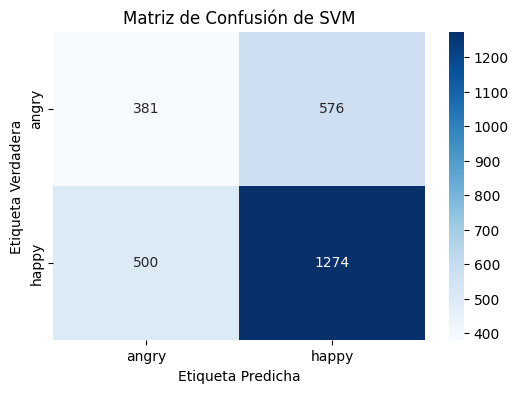

=== Validación Cruzada ===
Precisión con Validación Cruzada: 0.55 ± 0.02


In [ ]:
#@title MODELO SVM - CLASIFICADOR - DATOS BALANCEADOS
# Convertir a arrays de NumPy

#Entrenar SVM
# Entrenar el modelo SVM con los datos balanceados
svm_classifier = SVC(kernel='linear', probability=True, random_state=42, class_weight='balanced')
svm_classifier.fit(train_features_balanced, train_labels_balanced)

# Hacer predicciones en los datos de prueba
svm_predictions = svm_classifier.predict(test_features_scaled)

# Evaluación del modelo
print("=== Evaluación SVM ===")
svm_accuracy = accuracy_score(test_labels, svm_predictions)
print(f"Precisión: {svm_accuracy:.2f}")

svm_conf_matrix = confusion_matrix(test_labels, svm_predictions)
print("Informe de Clasificación:")
print(classification_report(test_labels, svm_predictions, target_names=['angry', 'happy']))

# Función para graficar la matriz de confusión
def plot_confusion_matrix(cm, title):
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['angry', 'happy'], yticklabels=['angry', 'happy'])
    plt.ylabel('Etiqueta Verdadera')
    plt.xlabel('Etiqueta Predicha')
    plt.title(title)
    plt.show()

# Graficar la matriz de confusión
plot_confusion_matrix(svm_conf_matrix, "Matriz de Confusión de SVM")

# Validación cruzada
print("=== Validación Cruzada ===")
svm_cv_scores = cross_val_score(svm_classifier, train_features_balanced, train_labels_balanced, cv=5)
print(f"Precisión con Validación Cruzada: {svm_cv_scores.mean():.2f} ± {svm_cv_scores.std():.2f}")

Dimensiones de las características aumentadas: (32082, 8)
Cantidad de etiquetas aumentadas: 32082
=== Sobremuestreo Tradicional ===
Precisión: 0.45
              precision    recall  f1-score   support

       angry       0.33      0.57      0.42       957
       happy       0.62      0.38      0.47      1774

    accuracy                           0.45      2731
   macro avg       0.48      0.48      0.45      2731
weighted avg       0.52      0.45      0.46      2731



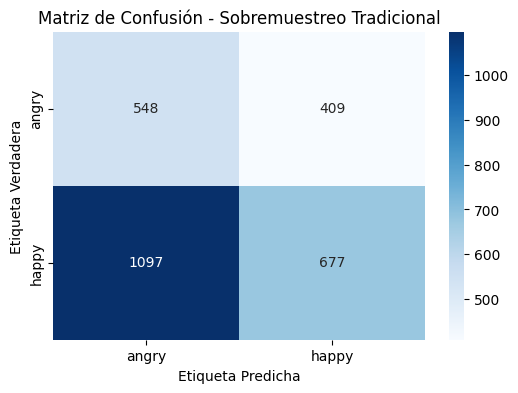

=== Data Augmentation ===
Precisión: 0.47
              precision    recall  f1-score   support

       angry       0.34      0.54      0.42       957
       happy       0.63      0.42      0.51      1774

    accuracy                           0.47      2731
   macro avg       0.49      0.48      0.46      2731
weighted avg       0.53      0.47      0.48      2731



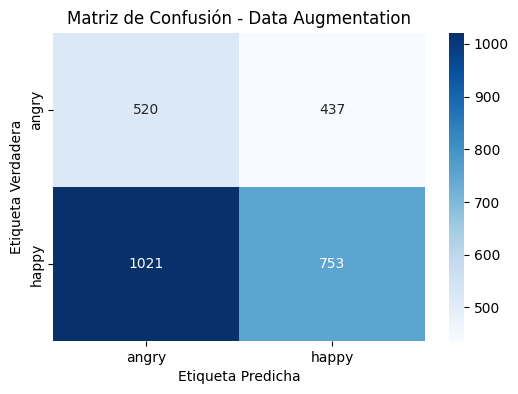

In [ ]:
#@title SOBREMUESTREO VS DATA AUGMENTATION MODELO SVM
def data_augmentation(features, labels, n_augment=2, noise_factor=0.01):
    augmented_features = []
    augmented_labels = []

    for feature, label in zip(features, labels):
        # Asegúrate de que la característica sea un vector de tamaño 8
        feature = np.array(feature)

        # Agregar la característica original
        augmented_features.append(feature)
        augmented_labels.append(label)

        # Generar características aumentadas agregando ruido
        for _ in range(n_augment):
            noise = np.random.normal(0, noise_factor, feature.shape)
            augmented_feature = feature + noise
            augmented_features.append(augmented_feature)
            augmented_labels.append(label)

    # Convertir a arrays numpy
    return np.array(augmented_features), np.array(augmented_labels)



def oversample_data(features, labels):
    # Combinar características y etiquetas
    data = np.column_stack((features, labels))

    # Separar por clases
    angry_data = data[data[:, -1] == 0]  # Clase 'angry'
    happy_data = data[data[:, -1] == 1]  # Clase 'happy'

    # Sobremuestrear la clase minoritaria 'angry' para igualarla con 'happy'
    angry_upsampled = resample(angry_data,
                               replace=True,
                               n_samples=len(happy_data),
                               random_state=42)

    # Reunir las clases balanceadas
    upsampled_data = np.vstack((angry_upsampled, happy_data))

    # Separar características y etiquetas nuevamente
    upsampled_features = upsampled_data[:, :-1]
    upsampled_labels = upsampled_data[:, -1]

    return upsampled_features, upsampled_labels

train_features_os, train_labels_os = oversample_data(train_features, train_labels)
train_features_aug, train_labels_aug = data_augmentation(train_features, train_labels)
print(f"Dimensiones de las características aumentadas: {train_features_aug.shape}")
print(f"Cantidad de etiquetas aumentadas: {len(train_labels_aug)}")


def plot_confusion_matrix(cm, title):
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['angry', 'happy'], yticklabels=['angry', 'happy'])
    plt.ylabel('Etiqueta Verdadera')
    plt.xlabel('Etiqueta Predicha')
    plt.title(title)
    plt.show()


def train_and_evaluate_svm(features, labels, test_features, test_labels, title):
    svm_classifier = SVC(kernel='linear', probability=True, random_state=42, class_weight='balanced')
    svm_classifier.fit(features, labels)

    predictions = svm_classifier.predict(test_features)

    print(f"=== {title} ===")
    print(f"Precisión: {accuracy_score(test_labels, predictions):.2f}")
    print(classification_report(test_labels, predictions, target_names=['angry', 'happy']))

    cm = confusion_matrix(test_labels, predictions)
    plot_confusion_matrix(cm, f"Matriz de Confusión - {title}")

# Evaluar con sobremuestreo
train_and_evaluate_svm(train_features_os, train_labels_os, test_features_scaled, test_labels, "Sobremuestreo Tradicional")

# Evaluar con Data Augmentation
train_and_evaluate_svm(train_features_aug, train_labels_aug, test_features_scaled, test_labels, "Data Augmentation")

In [ ]:
#@title AJUSTE DE HIPERPARAMETROS PARA KNN Y SVM
# SVM
# svm_param_grid = {
#     'C': [0.1, 1, 10, 100],
#     'kernel': ['linear', 'rbf', 'poly'],
#     'gamma': ['scale', 'auto']
# }
# svm_grid = GridSearchCV(SVC(probability=True, random_state=42), svm_param_grid, cv=5, scoring='accuracy')
# svm_grid.fit(train_features_scaled, train_labels)
# print(f"Mejores parámetros para SVM: {svm_grid.best_params_}")
# print(f"Mejor precisión de SVM: {svm_grid.best_score_:.2f}")
# best_svm = svm_grid.best_estimator_
# svm_best_predictions = best_svm.predict(test_features_scaled)
# print(f"Precisión del mejor SVM: {accuracy_score(test_labels, svm_best_predictions):.2f}")

# # KNN
# knn_param_grid = {
#     'n_neighbors': list(range(1, 31)),
#     'weights': ['uniform', 'distance'],
#     'metric': ['euclidean', 'manhattan', 'minkowski']
# }
# knn_grid = GridSearchCV(KNeighborsClassifier(), knn_param_grid, cv=5, scoring='accuracy')
# knn_grid.fit(train_features_scaled, train_labels)
# print(f"Mejores parámetros para KNN: {knn_grid.best_params_}")
# print(f"Mejor precisión de KNN: {knn_grid.best_score_:.2f}")
# best_knn = knn_grid.best_estimator_
# knn_best_predictions = best_knn.predict(test_features_scaled)
# print(f"Precisión del mejor KNN: {accuracy_score(test_labels, knn_best_predictions):.2f}")




# Escalar las características de entrenamiento y prueba
scaler = StandardScaler()
train_features_scaled = scaler.fit_transform(train_features)
test_features_scaled = scaler.transform(test_features)

# --------------------------
# Búsqueda en Cuadrícula - SVM
# --------------------------
svm_param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}

svm_grid = GridSearchCV(SVC(probability=True, random_state=42),
                        svm_param_grid,
                        cv=5,
                        scoring='accuracy',
                        n_jobs=-1)  # Usar múltiples núcleos

svm_grid.fit(train_features_scaled, train_labels)

print(f"Mejores parámetros para SVM: {svm_grid.best_params_}")
print(f"Mejor precisión de SVM: {svm_grid.best_score_:.2f}")

# Evaluar el mejor modelo SVM en el conjunto de prueba
best_svm = svm_grid.best_estimator_
svm_best_predictions = best_svm.predict(test_features_scaled)

print(f"Precisión del mejor SVM: {accuracy_score(test_labels, svm_best_predictions):.2f}")
print("=== Classification Report (SVM) ===")
print(classification_report(test_labels, svm_best_predictions, target_names=["Angry", "Happy"]))
print("=== Confusion Matrix (SVM) ===")
print(confusion_matrix(test_labels, svm_best_predictions))

# --------------------------
# Búsqueda en Cuadrícula - KNN
# --------------------------
knn_param_grid = {
    'n_neighbors': list(range(1, 21)),  # Reducido para pruebas rápidas
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

knn_grid = GridSearchCV(KNeighborsClassifier(),
                        knn_param_grid,
                        cv=5,
                        scoring='accuracy',
                        n_jobs=-1)

knn_grid.fit(train_features_scaled, train_labels)

print(f"Mejores parámetros para KNN: {knn_grid.best_params_}")
print(f"Mejor precisión de KNN: {knn_grid.best_score_:.2f}")

# Evaluar el mejor modelo KNN en el conjunto de prueba
best_knn = knn_grid.best_estimator_
knn_best_predictions = best_knn.predict(test_features_scaled)

print(f"Precisión del mejor KNN: {accuracy_score(test_labels, knn_best_predictions):.2f}")
print("=== Classification Report (KNN) ===")
print(classification_report(test_labels, knn_best_predictions, target_names=["Angry", "Happy"]))
print("=== Confusion Matrix (KNN) ===")
print(confusion_matrix(test_labels, knn_best_predictions))

Mejores parámetros para SVM: {'C': 10, 'gamma': 'auto', 'kernel': 'rbf'}
Mejor precisión de SVM: 0.64
Precisión del mejor SVM: 0.61
=== Classification Report (SVM) ===
              precision    recall  f1-score   support

       Angry       0.61      0.62      0.61      1774
       Happy       0.61      0.60      0.61      1774

    accuracy                           0.61      3548
   macro avg       0.61      0.61      0.61      3548
weighted avg       0.61      0.61      0.61      3548

=== Confusion Matrix (SVM) ===
[[1096  678]
 [ 709 1065]]
Mejores parámetros para KNN: {'metric': 'manhattan', 'n_neighbors': 1, 'weights': 'uniform'}
Mejor precisión de KNN: 0.77
Precisión del mejor KNN: 0.59
=== Classification Report (KNN) ===
              precision    recall  f1-score   support

       Angry       0.63      0.46      0.53      1774
       Happy       0.57      0.73      0.64      1774

    accuracy                           0.59      3548
   macro avg       0.60      0.59      0.

In [ ]:
#@title ELIMINAR IMAGENES NULAS
# Función para verificar si una imagen es completamente negra
def is_black_image(image):
    return np.max(image) == np.min(image)

# Función para eliminar las imágenes negras de una carpeta
def remove_black_images(folder_path):
    emotions = ['angry', 'happy']  # Subcarpetas de emociones
    total_removed = 0  # Contador de imágenes eliminadas

    # Iterar sobre las carpetas de emociones
    for emotion in emotions:
        emotion_folder = os.path.join(folder_path, emotion)

        if not os.path.exists(emotion_folder):
            print(f"La carpeta {emotion_folder} no existe.")
            continue

        print(f"Procesando carpeta: {emotion_folder}")

        # Iterar sobre las imágenes en la carpeta
        for filename in os.listdir(emotion_folder):
            image_path = os.path.join(emotion_folder, filename)

            if filename.endswith('.jpg') or filename.endswith('.png'):
                # Leer la imagen en escala de grises
                image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

                # Verificar si la imagen es negra
                if is_black_image(image):
                    os.remove(image_path)  # Eliminar la imagen negra
                    total_removed += 1
                    print(f"Eliminada imagen negra: {filename}")

    print(f"Total de imágenes negras eliminadas en {folder_path}: {total_removed}")

# Eliminar imágenes negras de los conjuntos train y test
remove_black_images(train_dir)
remove_black_images(test_dir)

Procesando carpeta: /content/drive/MyDrive/train-emotions/angry
Eliminada imagen negra: Training_78540321.jpg
Eliminada imagen negra: Training_52563817.jpg
Eliminada imagen negra: Training_28756096.jpg
Eliminada imagen negra: Training_32571770.jpg
Eliminada imagen negra: Training_10131352.jpg
Procesando carpeta: /content/drive/MyDrive/train-emotions/happy
Eliminada imagen negra: Training_87607167.jpg
Total de imágenes negras eliminadas en /content/drive/MyDrive/train-emotions: 6
Procesando carpeta: /content/drive/MyDrive/test-emotions/angry
Eliminada imagen negra: PublicTest_5543497.jpg
Procesando carpeta: /content/drive/MyDrive/test-emotions/happy
Total de imágenes negras eliminadas en /content/drive/MyDrive/test-emotions: 1


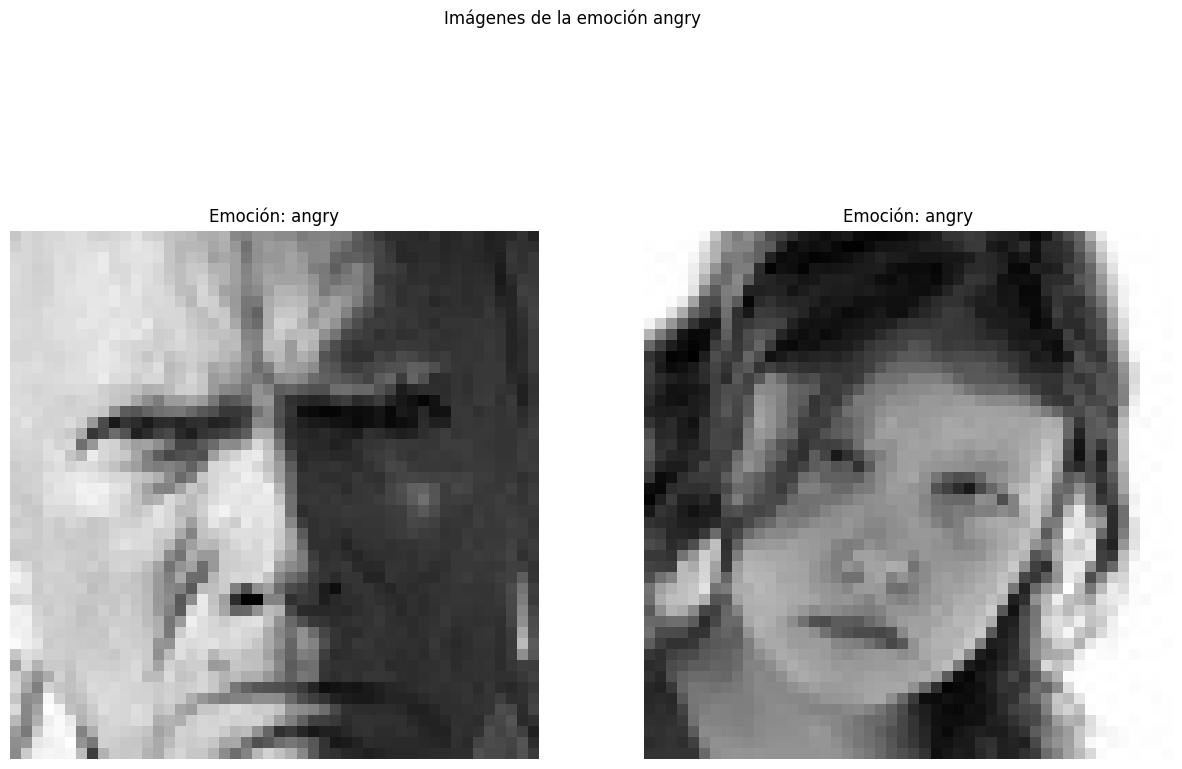

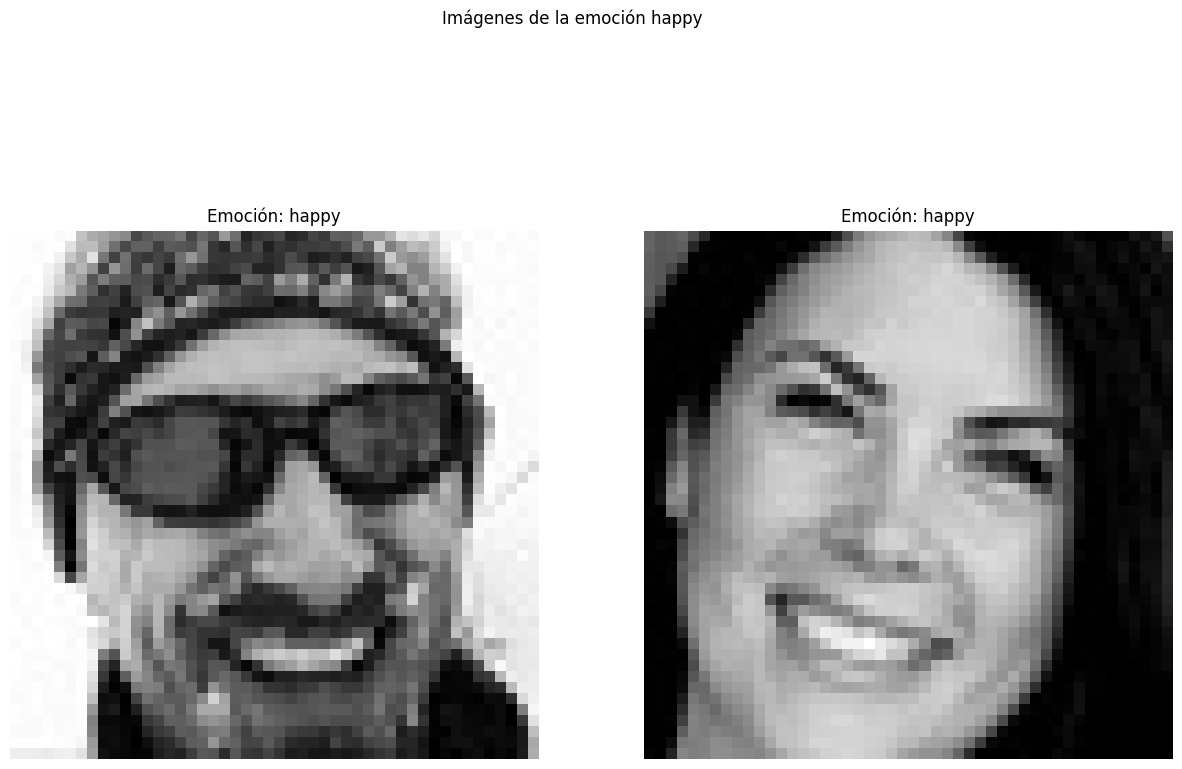

In [ ]:
#@title MOSTRAR IMAGENES DE EJEMPLO
def load_and_show_images(folder_path, num_images=5):
    # Definir las emociones y sus etiquetas
    emotion_folders = {'angry': 0, 'happy': 1}

    for emotion, label in emotion_folders.items():
        emotion_folder = os.path.join(folder_path, emotion)
        image_paths = os.listdir(emotion_folder)[:num_images]  # Limitar a num_images

        plt.figure(figsize=(15, 10))
        for i, image_file in enumerate(image_paths):
            image_path = os.path.join(emotion_folder, image_file)
            image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

            plt.subplot(1, num_images, i + 1)
            plt.imshow(image, cmap='gray')
            plt.title(f'Emoción: {emotion}')
            plt.axis('off')

        plt.suptitle(f'Imágenes de la emoción {emotion}')
        plt.show()

# Usar la función para mostrar imágenes desde las carpetas de entrenamiento o prueba
load_and_show_images(train_dir, num_images=2)  # Mostrar 5 imágenes de train-emotions
# load_and_show_images(test_dir, num_images=2)   # Mostrar 5 imágenes de test-emotions